# Power Analysis

This notebook calculates how many **Articles (N)** and **Seeds (R)** you need for a statistically sound comparison between two LLM configurations.

This notebook implements a **Paired Experimental Design** to compare two LLM configurations. To ensure the results are not due to chance, we account for two primary sources of variance:
1. **Article Variance ($\sigma_{data}$):** Difference in difficulty between scientific papers.
2. **Seed Variance ($\sigma_{seed}$):** Non-determinism in LLM outputs (noise).

Our goal is to find the minimum number of articles ($N$) and seeds ($R$) required to detect a specific improvement ($\Delta$) in F1-score with a statistical power of $1-\beta = 0.80$ and a significance level of $\alpha = 0.05$.

## Setup & Config

In [1]:
import os, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime
from IPython.display import display, Markdown

from ae.core.evaluation import ExperimentMatcher
from ae.core.tasks.loader import load_task_from_yaml
from ae.core.config.environments import load_settings_for_environment
from ae.core.llm import setup_teacher
from power_analysis import *

# Settings
ALPHA, POWER, DELTA = 0.05, 0.80, 0.03
SEED_THRESHOLD = 0.10

PROJECT_ROOT = Path.cwd().parent.parent
PILOT_DIR = PROJECT_ROOT / "research/local_data/extractions/exp_test/pilot/"
GT_PATH = PROJECT_ROOT / "data/ground_truth/nanozymes.csv"
TASK_PATH = PROJECT_ROOT / "config/tasks/nanozymes.yaml"
LLM_CONFIG = PROJECT_ROOT / "config/systems/test.yaml"

task = load_task_from_yaml(TASK_PATH)
print(f"✓ Configured for task: {task.name}")

✓ Configured for task: nanozymes


In [2]:
# Initialize Matcher & Load Data
try:
    teacher = setup_teacher(config=load_settings_for_environment(custom_config=LLM_CONFIG))
    print(f"✓ LLM Judge ready: {teacher.model}")
except:
    teacher = None
    print("⚠️ No LLM Judge. Using exact matching.")

matcher = ExperimentMatcher(
    fields_to_compare=task.compare_fields,
    float_tolerance=0.05,
    teacher_llm=teacher,
    enable_semantic_judge=(teacher is not None)
)

pilot_data = scan_pilot_directory(PILOT_DIR)
gt_lookup = pd.read_csv(GT_PATH).drop_duplicates(subset=["pdf"]).set_index("pdf").to_dict('index')

valid_ids = sorted({f.stem for s in pilot_data.values() for sd in s.values() for f in sd} & set(gt_lookup.keys()))

print(f"✓ Data loaded. {len(valid_ids)} articles matched with Ground Truth.")

✓ LLM Judge ready: gpt-oss:120b
✓ Data loaded. 3 articles matched with Ground Truth.


## Calculation

**1. Variance Decomposition via Mixed-Effects Model**

To separate the "signal" (differences between configurations) from the "noise" (seed variability), we use a **Linear Mixed-Effects Model (LMM)**:
$$F1_{ij} = \beta_0 + \beta_{config} + u_i + \epsilon_{ij}$$
Where:
* $u_i \sim \mathcal{N}(0, \sigma^2_{data})$ is the random effect for the $i$-th article.
* $\epsilon_{ij} \sim \mathcal{N}(0, \sigma^2_{seed})$ is the residual error (seed noise).

**2. Standard Deviation of Differences ($\sigma_d$)**

Since we use a paired design (running both configs on the same articles), the power depends on the standard deviation of the paired differences $d_i = F1_{A,i} - F1_{B,i}$. We use **Bootstrap Resampling** to obtain a robust estimate of $\sigma_d$:
$$\sigma_d = \sqrt{\text{Var}(F1_A - F1_B)}$$

---

**3. Estimating $N$ (Articles)**

We calculate the required number of articles using the **t-distribution** power formula. This accounts for the heavy tails present in small pilot samples:
$$N \approx \left( \frac{(t_{\alpha/2, df} + t_{\beta, df}) \cdot \sigma_d}{\Delta} \right)^2$$
The calculation is performed iteratively until $N$ converges, as the degrees of freedom ($df = N-1$) depend on $N$.

**4. Estimating $R$ (Seeds)**

To prevent LLM noise from overwhelming the article variance, we optimize the number of seeds ($R$) such that the seed-induced variance contributes no more than a threshold $T$ (e.g., 10%) to the total variance:
$$R \geq \left( \frac{\sigma_{seed}}{\sigma_{data}} \right)^2 \cdot \frac{1-T}{T}$$

**5. Validation (Standard Error)**

Finally, we verify that the **Standard Error (SE)** of our design meets the threshold required to detect $\Delta$:
$$SE = \frac{\sigma_d}{\sqrt{N}} \leq \frac{\Delta}{z_{\alpha/2} + z_{\beta}}$$

In [ ]:
# Core computation
results = []

for sys_id, seeds in pilot_data.items():
    for seed_id, files in seeds.items():
        for f in files:
            if f.stem in valid_ids:
                _, f1 = compute_f1_for_extraction(
                    f, gt_lookup, matcher, task.compare_fields, task.name
                )
                results.append({
                    'config': f"system_{sys_id}",
                    'seed': seed_id,
                    'article_id': f.stem,
                    'f1': f1
                })

df = pd.DataFrame(results)

# NEW: unified pipeline
analysis = perform_power_analysis(
    df,
    delta=DELTA,
    alpha=ALPHA,
    power=POWER,
    seed_variance_threshold=SEED_THRESHOLD
)

var = analysis.variance
rec_N = analysis.recommended_N
rec_R = analysis.recommended_R

SE = analysis.se
SE_limit = analysis.se_threshold

print("✓ Calculations complete.")

## Results

## 🎯 Experimental Design for $\Delta = 0.03$

**Recommended N (Articles):** `19`

**Recommended R (Seeds):** `3`

### Paired F1 Performance

config,system_1,system_2,diff
article_id,,,
AC503544W,0.650,0.462,0.188
ACS.ANALCHEM.2C05425,0.700,0.632,0.068
ACS.ANALCHEM.7B02880,0.950,0.842,0.108



**Stats Summary:**
- Paired StdDev ($\sigma_d$): `0.0439`
- Standard Error: `0.0101` (Target: `< 0.0101`) ✅
- Test choice: `paired t-test`
- Normality p-value: `0.6273`


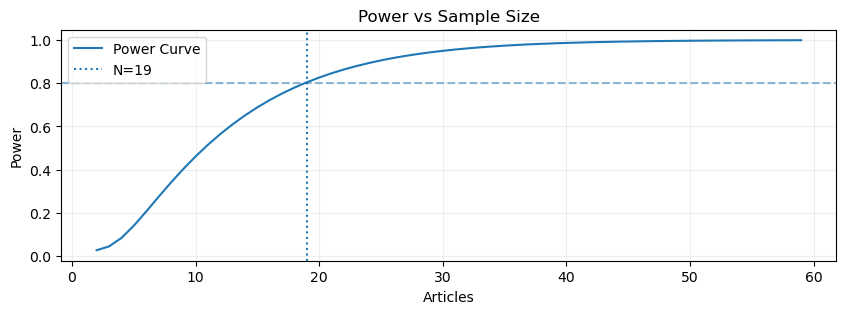

In [4]:
display(Markdown(f"## 🎯 Experimental Design for $\\Delta = {DELTA}$"))

display(Markdown(f"**Recommended N (Articles):** `{rec_N}`"))
display(Markdown(f"**Recommended R (Seeds):** `{rec_R}`"))

# Safe pivot (FIXED)
pivot = df.pivot_table(index='article_id', columns='config', values='f1', aggfunc='mean')

if len(pivot.columns) >= 2:
    configs = sorted(pivot.columns)
    pivot['diff'] = pivot[configs[0]] - pivot[configs[1]]

    display(Markdown("### Paired F1 Performance"))
    display(pivot.style.format('{:.3f}').background_gradient(subset=['diff'], cmap='RdYlGn', vmin=-0.1, vmax=0.1))

display(Markdown(f"""
**Stats Summary:**
- Paired StdDev ($\\sigma_d$): `{var.sigma_d:.4f}`
- Standard Error: `{SE:.4f}` (Target: `< {SE_limit:.4f}`) {'✅' if SE <= SE_limit else '❌'}
- Test choice: `{analysis.test_choice}`
- Normality p-value: `{analysis.shapiro_p:.4f}`
"""))

# Power Curve
plt.figure(figsize=(10, 3))
n_range = np.arange(2, max(60, rec_N + 20))
plt.plot(n_range, compute_power_curve(n_range, var.sigma_d, DELTA, ALPHA), label='Power Curve')
plt.axhline(POWER, linestyle='--', alpha=0.5)
plt.axvline(rec_N, linestyle=':', label=f'N={rec_N}')
plt.title("Power vs Sample Size")
plt.xlabel("Articles")
plt.ylabel("Power")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Export

In [ ]:
out = {
    "N": int(rec_N),
    "R": int(rec_R),
    "sigma_d": var.sigma_d,
    "timestamp": datetime.now().isoformat()
}

with open(PROJECT_ROOT / "research/power_analysis_results.json", 'w') as f:
    json.dump(out, f, indent=2)

print("✓ Exported to JSON.")